<a href="https://colab.research.google.com/github/DANFELcode/ptia-fitqual-ai/blob/main/fitqual_entrenamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FitQual AI: reconocimiento de alimentos por imagen

### Proyecto de curso PTIA · Escuela Colombiana de Ingeniería Julio Garavito · Grupo 2

**Integrantes:** Daniel Felipe Sua, Juan David Munar

**Fecha de publicacion:** 12/10/2026



### 0. Configuración

Montamos Google Drive para guardar los pesos del modelo y el historial de entrenamiento. Colab borra la memoria de la sesión al reiniciarse o desconectarse, y el entrenamiento completo tarda unos 50 minutos.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Diseño del problema y del modelo

**Tipo de problema.** Clasificación de imagen con 101 clases (Food-101). Cada foto contiene un alimento o plato, y el modelo debe decir cuál es.

**Entrada y salida.** La entrada es una imagen RGB de 224×224 píxeles. La salida es una distribución de probabilidad sobre las 101 clases, de la que se toma el Top-3 con su confianza.

**Modelo.** Usamos MobileNetV3 preentrenado en ImageNet como extractor de características (transfer learning). Primero se entrena solo la parte final: pooling global, Dropout y una capa densa de 101 neuronas con softmax. Un afinado de las capas del extractor queda como paso opcional.

**Entrenamiento.** La pérdida es Sparse Categorical Crossentropy, porque las etiquetas son enteros y no vectores one-hot. El optimizador es AdamW con learning rate bajo, y la regularización combina Dropout y weight decay.

**Métricas.** Top-1 (la clase correcta es la primera predicción) y Top-5 (está entre las cinco primeras). Las metas numéricas se fijarán después de la primera corrida.


## Problema

Llevar el control de lo que se come exige, en cada comida, una secuencia de tareas manuales. Primero hay que identificar los alimentos del plato. Luego hay que buscar cada uno en una aplicación o tabla nutricional, donde a menudo existen varias entradas parecidas. Después hay que estimar cuánto se comió, normalmente a ojo, porque pocas personas pesan su comida. Por último hay que digitar o seleccionar los valores. Un plato con varios componentes, como arroz, carne, papa y ensalada, repite este proceso para cada uno.

Esa carga se repite varias veces al día, todos los días. Quien tiene una agenda ocupada la percibe como una obligación tediosa y no como una ayuda. Cuando registrar cuesta más que el beneficio que da, la persona omite comidas, registra de forma incompleta o abandona el seguimiento.

El problema tiene además una consecuencia práctica: el registro incompleto o impreciso produce datos poco confiables. Un seguimiento que no refleja lo que realmente se comió no sirve para tomar decisiones sobre la alimentación.

El problema que aborda FitQual AI es el tiempo y la fricción del registro manual de alimentos, y en particular su primer paso: reconocer qué alimento hay en el plato. Es el paso que más depende del usuario, que debe nombrar el alimento y elegirlo entre varias entradas parecidas, y también el que mejor se presta a resolverse con visión por computadora. Si el sistema lo identifica a partir de una foto, el usuario solo confirma o corrige lo que propone.

## Alcance de este notebook
- Un alimento o plato por foto (clasificación de imagen).
- Porción estándar, sin medición real del tamaño.
- Resultados preliminares para el Hito 2.

## 2. Datos y análisis exploratorio

### 2.1 Carga y preparación de los datos

Cargamos Food-101 desde tensorflow_datasets. El train oficial (75.750 imágenes) se divide en 90 % para entrenamiento y 10 % para validación, y el conjunto de prueba oficial (25.250 imágenes) se deja intacto para la evaluación final. Todas las imágenes se redimensionan a 224×224, el tamaño que espera MobileNetV3, y se procesan por lotes de 64. En entrenamiento se aplica augmentation (volteo horizontal, zoom y contraste aleatorios) para que el modelo vea variaciones de cada foto. En validación y prueba no se aplica, para que midan el rendimiento sobre imágenes reales.

In [ ]:
!pip install importlib_resources
!rm -rf /root/tensorflow_datasets/food101

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras

print(tf.config.list_physical_devices("GPU"))

(train_ds, val_ds, test_ds), info = tfds.load(
    "food101",
    split=["train[:90%]", "train[90%:]", "validation"],
    as_supervised=True,
    with_info=True,
)
class_names = info.features["label"].names
print(info.splits["train"].num_examples, info.splits["validation"].num_examples, len(class_names))

IMG_SIZE = (224, 224)
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE

augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomZoom(0.2),
    keras.layers.RandomContrast(0.2),
])

def prep(img, label):
    return tf.image.resize(img, IMG_SIZE), label

train_ds = (train_ds.map(prep, AUTOTUNE).shuffle(1000).batch(BATCH)
            .map(lambda x, y: (augment(x, training=True), y), AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds = val_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test_ds = test_ds.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.E8NB1R_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.E8NB1R_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.
75750 25250 101


In [ ]:
print(info.splits["train"].num_examples, info.splits["validation"].num_examples, len(class_names))
print(class_names[:5])

75750 25250 101
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']


### 2.2 Comprobación de los lotes

Verificamos que un lote tenga la forma esperada: 64 imágenes de 224×224 con 3 canales, 64 etiquetas, y píxeles en el rango 0 a 255. No normalizamos a mano porque MobileNetV3 en Keras ya incluye el reescalado.

In [ ]:
x, y = next(iter(train_ds))
print(x.shape, y.shape, float(tf.reduce_max(x)))

(64, 224, 224, 3) (64,) 255.0


### 2.3 Análisis exploratorio

Food-101 no es una tabla, así que no hay nulos ni columnas que limpiar. El análisis se centra en tres cosas:
 (1) cuántas imágenes hay por clase, para confirmar que el conjunto está balanceado;
  (2) una muestra de imágenes con su etiqueta, para ver qué tan variadas son las fotos; y
   (3) el efecto de la augmentation sobre una misma imagen. Las imágenes de entrenamiento de Food-101 tienen ruido deliberado (etiquetas o fotos imperfectas), lo que se declara como limitación.

#### 2.3.1 Imágenes por clase

Contamos cuántas imágenes del train oficial hay por clase. Food-101 documenta 750 por clase, y esto lo comprueba. Si el conjunto está balanceado, ninguna clase tiene ventaja por tener más ejemplos y Top-1 y Top-5 se leen sin sesgo por frecuencia. Leemos solo las etiquetas, sin decodificar las imágenes, para que el conteo sea rápido.

In [ ]:
import numpy as np

raw = tfds.load(
    "food101",
    split="train",
    as_supervised=True,
    decoders={"image": tfds.decode.SkipDecoding()},
)
labels = np.array([int(y) for _, y in raw])
conteo = np.bincount(labels, minlength=101)
print(conteo.min(), conteo.max(), conteo.sum())

750 750 75750


El minimo y maximo por clase son iguales y el total coincide con el train

#### 2.3.2 Clases del dataset

Listamos las 101 clases de Food-101 para ver qué tipos de alimento reconoce el modelo. Son platos preparados, no ingredientes sueltos, lo que condiciona el uso que se le puede dar en FitQual AI.

In [ ]:
for i, nombre in enumerate(class_names):
    print(i, nombre)

0 apple_pie
1 baby_back_ribs
2 baklava
3 beef_carpaccio
4 beef_tartare
5 beet_salad
6 beignets
7 bibimbap
8 bread_pudding
9 breakfast_burrito
10 bruschetta
11 caesar_salad
12 cannoli
13 caprese_salad
14 carrot_cake
15 ceviche
16 cheesecake
17 cheese_plate
18 chicken_curry
19 chicken_quesadilla
20 chicken_wings
21 chocolate_cake
22 chocolate_mousse
23 churros
24 clam_chowder
25 club_sandwich
26 crab_cakes
27 creme_brulee
28 croque_madame
29 cup_cakes
30 deviled_eggs
31 donuts
32 dumplings
33 edamame
34 eggs_benedict
35 escargots
36 falafel
37 filet_mignon
38 fish_and_chips
39 foie_gras
40 french_fries
41 french_onion_soup
42 french_toast
43 fried_calamari
44 fried_rice
45 frozen_yogurt
46 garlic_bread
47 gnocchi
48 greek_salad
49 grilled_cheese_sandwich
50 grilled_salmon
51 guacamole
52 gyoza
53 hamburger
54 hot_and_sour_soup
55 hot_dog
56 huevos_rancheros
57 hummus
58 ice_cream
59 lasagna
60 lobster_bisque
61 lobster_roll_sandwich
62 macaroni_and_cheese
63 macarons
64 miso_soup
65 muss

#### 2.3.3 Distribución de imágenes por clase

Graficamos el conteo anterior. Si el conjunto está balanceado, todas las barras tienen la misma altura (750).

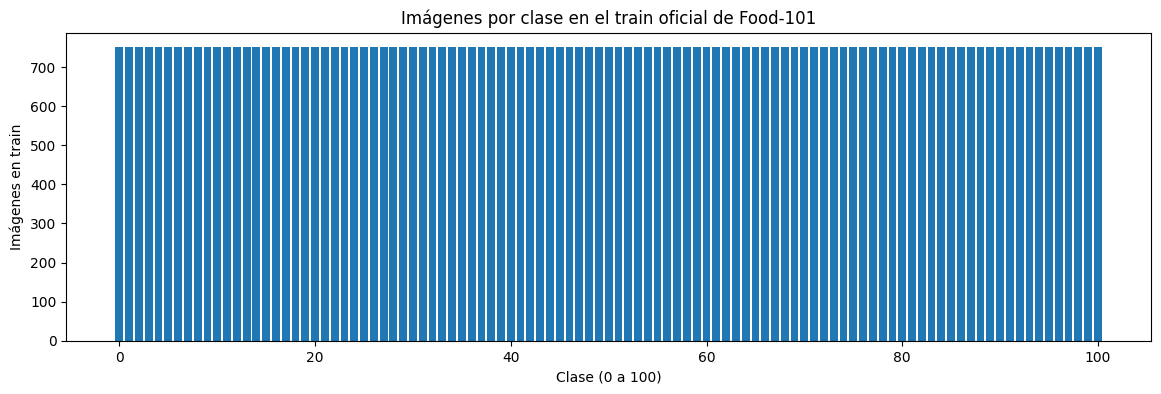

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.bar(range(101), conteo)
plt.xlabel("Clase (0 a 100)")
plt.ylabel("Imágenes en train")
plt.title("Imágenes por clase en el train oficial de Food-101")
plt.show()

#### 2.3.4 Muestra de imágenes

Mostramos una cuadrícula de imágenes de validación con su etiqueta, para ver qué tan variadas son las fotos (ángulo, luz, encuadre, fondo). Las imágenes ya están redimensionadas a 224×224 y no tienen augmentation.

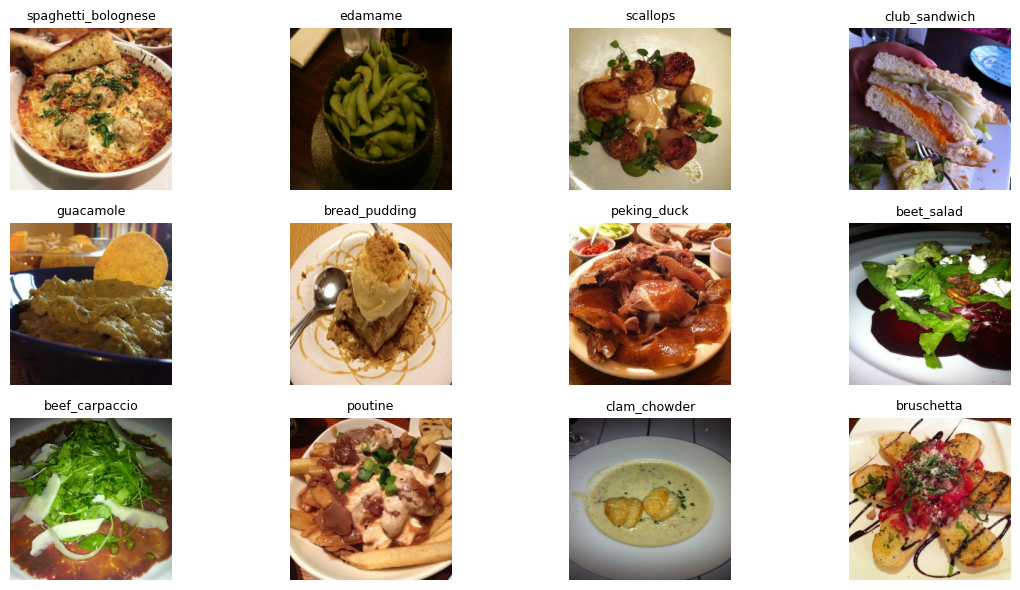

In [ ]:
import matplotlib.pyplot as plt

x, y = next(iter(val_ds))
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(class_names[int(y[i])], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

#### 2.3.5 Efecto de la augmentation

Tomamos una misma imagen de validación y le aplicamos la augmentation siete veces. Cada resultado es una versión distinta (volteada, con zoom o con otro contraste) de la misma foto, con la misma etiqueta. Así se ve lo que el modelo recibe en cada época durante el entrenamiento.

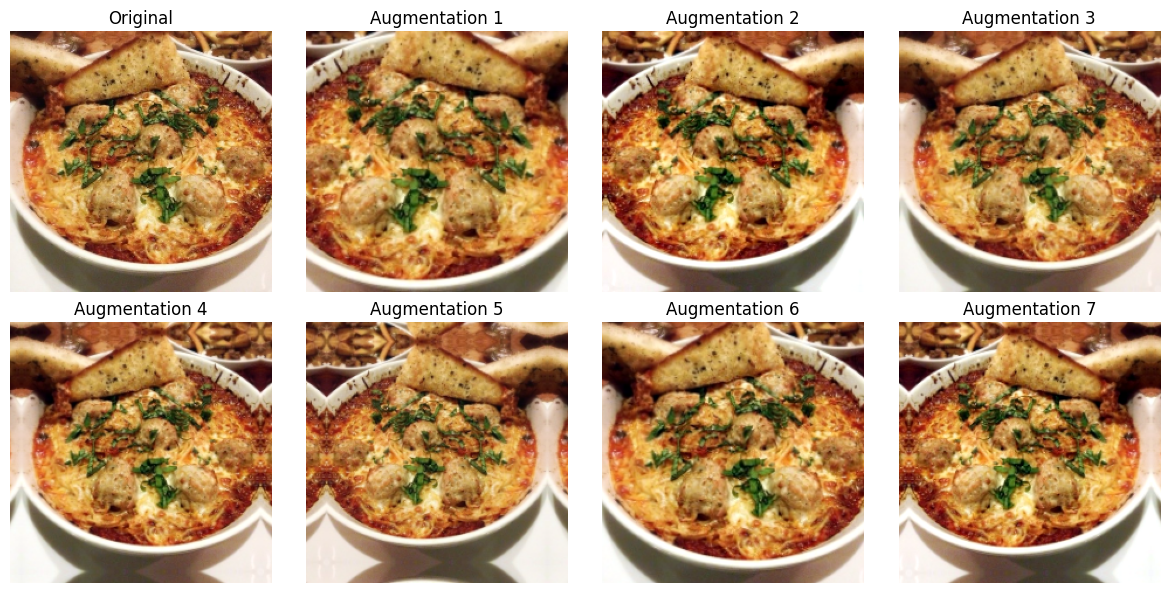

In [ ]:
x, y = next(iter(val_ds))
img = x[0:1]

plt.figure(figsize=(12, 6))
plt.subplot(2, 4, 1)
plt.imshow(img[0].numpy().astype("uint8"))
plt.title("Original")
plt.axis("off")

for i in range(7):
    aug = augment(img, training=True)
    aug = tf.clip_by_value(aug, 0, 255)
    plt.subplot(2, 4, i + 2)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.title(f"Augmentation {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

Augmentation ayuda a que el modelo generalice mejor, reconozca el plato en fotos que nunca vio y no solo en las de entrenamiento evitando overfitting

## 3. Modelo

### 3.1 Construcción del modelo

Usamos transfer learning: en vez de entrenar una red desde cero, partimos de MobileNetV3Large, que ya fue entrenada en ImageNet (millones de fotos) y aprendió a detectar bordes, texturas, colores y formas. Esa red hace de extractor de características: convierte cada foto en un conjunto de números que describe lo que contiene.

**Pesos congelados.** Los pesos son los números que el modelo ajusta al aprender. Congelar la base significa que no se modifican durante el entrenamiento. Así reutilizamos lo que ya sabe ver, entrenamos más rápido con menos datos y evitamos que los errores iniciales de la capa nueva (que parte al azar) dañen los pesos preentrenados.

Encima de la base agregamos tres componentes, que son los únicos que se entrenan:

1. **Pooling global (GlobalAveragePooling2D).** La base entrega, por cada foto, varios mapas de características. El pooling promedia cada mapa y deja un solo número por mapa, lo que resume la información en un vector corto.
2. **Dropout (0.2).** Durante el entrenamiento apaga al azar el 20 % de esos valores en cada paso. Así el modelo no depende de una sola señal y memoriza menos las imágenes de entrenamiento (reduce el overfitting). En validación, prueba e inferencia no se aplica.
3. **Capa densa de 101 neuronas con softmax.** Cada neurona combina el vector de entrada con sus propios pesos, y hay una por clase de Food-101. La función softmax convierte las 101 salidas en probabilidades que suman 1. De ahí se obtienen el Top-1, el Top-3 y el Top-5.

MobileNetV3 en Keras incluye el reescalado de píxeles, por eso no normalizamos a mano.

In [ ]:
base = keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)
base.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = base(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(101, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │        97,061 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,093,413 (11.80 MB)

 Trainable params: 97,061 (379.14 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

## 4. Entrenamiento y evaluación

### 4.1 Compilación del modelo

Antes de entrenar hay que decirle al modelo tres cosas:

- **Función de pérdida (Sparse Categorical Crossentropy).** Mide qué tan equivocada es la predicción: es alta si el modelo le da poca probabilidad a la clase correcta y baja si le da mucha. El entrenamiento busca reducirla. "Sparse" significa que las etiquetas son números enteros (0 a 100) y no vectores one-hot.
- **Optimizador (AdamW).** Es el algoritmo que ajusta los pesos para reducir la pérdida. Usamos un learning rate bajo (1e-3), que controla qué tan grande es cada ajuste: si es muy alto, el entrenamiento se vuelve inestable, y si es muy bajo, avanza demasiado lento. AdamW incluye weight decay (1e-4), que penaliza los pesos muy grandes y ayuda a reducir el overfitting.
- **Métricas.** Top-1 (la clase correcta es la primera predicción) y Top-5 (la clase correcta está entre las cinco primeras).

In [ ]:
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="top1"),
        keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5"),
    ],
)

### 4.2 Prueba rápida con un subconjunto

Antes del entrenamiento completo hacemos una prueba corta para detectar errores de código o de configuración sin esperar a que pase toda la base de datos. Entrenamos una sola época (una pasada completa por los datos de entrenamiento) con 50 lotes de entrenamiento (3.200 imágenes) y validamos con 10 lotes (640 imágenes). No buscamos buenos resultados, solo comprobar que el modelo entrena, que la pérdida es un número válido y que las métricas Top-1 y Top-5 se calculan.

In [ ]:
history_test = model.fit(
    train_ds.take(50),
    validation_data=val_ds.take(10),
    epochs=1,
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 58s 649ms/step - loss: 4.6182 - top1: 0.0603 - top5: 0.1828 - val_loss: 3.4940 - val_top1: 0.2125 - val_top5: 0.4359


El modelo entrena sin errores y las métricas se calculan bien. Con solo 50 lotes (3.200 imágenes) y una época, la pérdida de entrenamiento fue 4.61, casi la de adivinar al azar con 101 clases (ln 101 ≈ 4.61), porque el promedio incluye los primeros pasos, con la capa final todavía sin entrenar. En validación el modelo ya mejoró: Top-1 de 16.6 % y Top-5 de 42.5 %, frente a ~1 % y ~5 % del azar. Estas cifras no representan el rendimiento final, ya que la validación usó solo 640 imágenes. Se confirma que la configuración funciona y se pasa al entrenamiento completo.

### 4.3 Entrenamiento completo

Entrenamos con todo el conjunto de entrenamiento (68.175 imágenes) y validamos en cada época con las 7.575 imágenes de validación. Usamos 5 épocas como punto de partida. Cada época es una pasada completa por los datos. Al terminar cada una se miden la pérdida y las métricas Top-1 y Top-5 en entrenamiento y en validación, y se guardan en `history` para graficarlas.

In [21]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
)

Epoch 1/5
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 586s 548ms/step - loss: 2.1058 - top1: 0.4781 - top5: 0.7464 - val_loss: 1.5105 - val_top1: 0.6094 - val_top5: 0.8499
Epoch 2/5
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 578s 540ms/step - loss: 1.6394 - top1: 0.5836 - top5: 0.8263 - val_loss: 1.4143 - val_top1: 0.6379 - val_top5: 0.8581
Epoch 3/5
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 567s 529ms/step - loss: 1.5294 - top1: 0.6049 - top5: 0.8455 - val_loss: 1.3803 - val_top1: 0.6429 - val_top5: 0.8683
Epoch 4/5
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 747s 647ms/step - loss: 1.4747 - top1: 0.6188 - top5: 0.8533 - val_loss: 1.3529 - val_top1: 0.6494 - val_top5: 0.8708
Epoch 5/5
1066/1066 ━━━━━━━━━━━━━━━━━━━━ 608s 520ms/step - loss: 1.4418 - top1: 0.6245 - top5: 0.8601 - val_loss: 1.3452 - val_top1: 0.6597 - val_top5: 0.8738


Tras 5 épocas con la base congelada, la pérdida de validación bajó de 1.514 a 1.338 y el modelo alcanzó en validación un Top-1 de 66.4 % y un Top-5 de 87.2 %. No se observa overfitting, ya que la pérdida de validación sigue bajando junto con la de entrenamiento. Las métricas de validación son mejores que las de entrenamiento porque en entrenamiento están activos el Dropout y la augmentation, y las cifras son un promedio de toda la época. La mejora se vuelve más lenta hacia la época 5, lo que sugiere que con la base congelada el modelo se acerca a su límite.

#### Guardado del modelo entrenado

Guardamos en Google Drive los pesos del modelo y el historial de entrenamiento (pérdida y métricas de cada época). Así se pueden cargar después para evaluar, graficar las curvas y hacer inferencia sin volver a entrenar.

In [22]:
import json

model.save_weights("/content/drive/MyDrive/fitqual.weights.h5")
with open("/content/drive/MyDrive/fitqual_history.json", "w") as f:
    json.dump(history.history, f)
print("Guardado")

Guardado


### 4.4 Curvas de entrenamiento

Graficamos la pérdida y el Top-1 de entrenamiento y validación por época. Si ambas curvas bajan (o suben) juntas, el modelo generaliza. Si la de entrenamiento mejora y la de validación se estanca o empeora, hay overfitting.

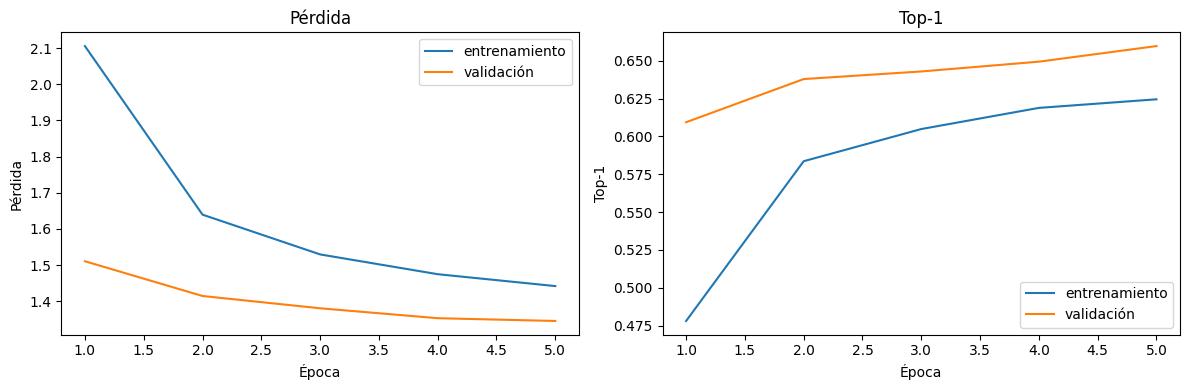

In [23]:
import matplotlib.pyplot as plt

epocas = range(1, 6)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epocas, history.history["loss"], label="entrenamiento")
plt.plot(epocas, history.history["val_loss"], label="validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epocas, history.history["top1"], label="entrenamiento")
plt.plot(epocas, history.history["val_top1"], label="validación")
plt.xlabel("Época")
plt.ylabel("Top-1")
plt.title("Top-1")
plt.legend()

plt.tight_layout()
plt.show()

### 4.5 Evaluación en el conjunto de prueba

Evaluamos el modelo final en el conjunto de prueba oficial de Food-101 (25.250 imágenes), que no se usó ni para entrenar ni para validar. Esta es la medición que reportamos como rendimiento del modelo, y se hace una sola vez, al final, para no ajustar decisiones mirando el test. Reportamos la pérdida, el Top-1 y el Top-5.

In [24]:
resultados = model.evaluate(test_ds, return_dict=True)
print(resultados)

395/395 ━━━━━━━━━━━━━━━━━━━━ 55s 139ms/step - loss: 1.1151 - top1: 0.6973 - top5: 0.9065
{'loss': 1.1151347160339355, 'top1': 0.6972673535346985, 'top5': 0.9065346717834473}


### Resultados en el conjunto de prueba

Con la base congelada y 5 épocas de entrenamiento, el modelo alcanza en el conjunto de prueba oficial una exactitud Top-1 de 69,7 % y Top-5 de 90,7 % (pérdida de 1,115). Top-1 es el porcentaje de fotos en las que la clase más probable es la correcta. Top-5 es el porcentaje en las que la clase correcta está entre las cinco más probables.

Las cifras de prueba son mejores que las de validación en la última época (66,0 % y 87,4 %). Una explicación probable es que la validación sale del conjunto de entrenamiento, que en Food-101 contiene ruido deliberado, mientras que el conjunto de prueba está limpio. Esta explicación no se verificó con un experimento.

Estos resultados son preliminares. Quedan por debajo de los valores de ejemplo de la retroalimentación (Top-1 ≥ 80 % y Top-5 ≥ 92 %), que eran ilustrativos. El Top-5 se acerca al ejemplo. El afinado de la base (descongelar capas) queda como mejora a evaluar.

### 4.6 Qué clases confunde el modelo

Para saber dónde falla el modelo, no solo cuánto, se guardan tres datos de cada foto de prueba: la clase real, la clase que predijo y su confianza (la probabilidad que el modelo asignó a esa predicción, entre 0 y 1). Luego se cuentan los errores más repetidos, es decir, los pares clase real - clase predicha. Esos pares son la base de la matriz de confusión: una tabla donde cada fila es la clase real, cada columna la predicha, y cada celda cuenta cuántas fotos cayeron ahí. Con 101 clases completa sería ilegible, así que después se dibuja solo con las clases más confundidas.

In [25]:
import numpy as np
from collections import Counter

y_true, y_pred, y_conf = [], [], []
for x, y in test_ds:
    p = model(x, training=False).numpy()
    y_true.extend(y.numpy())
    y_pred.extend(p.argmax(axis=1))
    y_conf.extend(p.max(axis=1))
y_true, y_pred, y_conf = map(np.array, (y_true, y_pred, y_conf))
print((y_true == y_pred).mean())

errores = Counter((int(a), int(b)) for a, b in zip(y_true, y_pred) if a != b)
for (real, pred), n in errores.most_common(10):
    print(f"{class_names[real]} -> {class_names[pred]}: {n}")

0.6972673267326732
filet_mignon -> steak: 57
pork_chop -> steak: 36
chocolate_cake -> chocolate_mousse: 35
ramen -> pho: 33
gnocchi -> ravioli: 32
spaghetti_bolognese -> spaghetti_carbonara: 30
lasagna -> ravioli: 30
club_sandwich -> grilled_cheese_sandwich: 30
apple_pie -> bread_pudding: 29
fried_rice -> risotto: 29


### Resultado: dónde falla el modelo

La exactitud calculada foto por foto (0,6973) coincide con la de la evaluación, lo que confirma que las predicciones se extrajeron bien. Los 10 errores más frecuentes ocurren entre clases visualmente parecidas:

- **Cortes de carne:** filet_mignon → steak (57 de 250 fotos de prueba) y pork_chop → steak (36).
- **Postres:** chocolate_cake → chocolate_mousse (35) y apple_pie → bread_pudding (29).
- **Pastas:** gnocchi → ravioli (32), lasagna → ravioli (30) y spaghetti_bolognese → spaghetti_carbonara (30).
- **Otros:** ramen → pho (33), club_sandwich → grilled_cheese_sandwich (30) y fried_rice → risotto (29).

Una explicación probable es que estos pares comparten colores, texturas y presentación, y que algunas etiquetas se solapan: un filet mignon es un tipo de steak. Esta explicación no se verificó con un análisis de las imágenes.

Para el uso de FitQual AI, esto respalda mostrar al usuario las tres mejores opciones cuando la confianza es baja: la clase correcta suele estar entre las más probables (Top-5 de 90,7 %), aunque no sea la primera.

### 4.7 Matriz de confusión de las clases más confundidas

Una matriz de confusión es una tabla donde cada fila es la clase real de la foto, cada columna es la clase que predijo el modelo y cada celda cuenta cuántas fotos cayeron en esa combinación. La diagonal son los aciertos (real = predicha) y todo lo que queda fuera de la diagonal son errores. Con 101 clases tendría más de 10.000 celdas y no se podría leer, así que se dibuja solo con las clases que aparecen en los 10 errores más frecuentes del paso anterior. Cada celda cuenta únicamente las fotos cuya clase real y predicha están dentro de ese grupo, por eso las filas no suman 250.

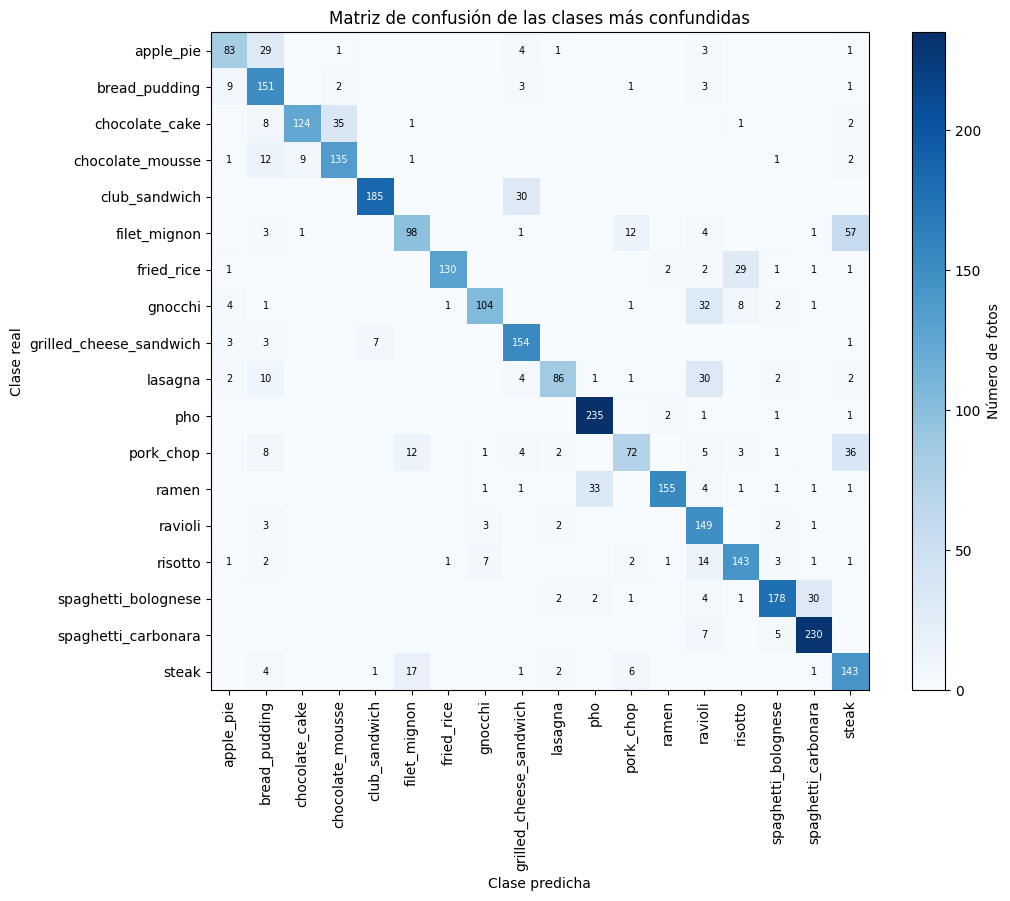

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

idx = sorted({c for par, _ in errores.most_common(10) for c in par})
nombres = [class_names[i] for i in idx]
m = confusion_matrix(y_true, y_pred, labels=idx)

plt.figure(figsize=(11, 9))
plt.imshow(m, cmap="Blues")
plt.colorbar(label="Número de fotos")
plt.xticks(range(len(idx)), nombres, rotation=90)
plt.yticks(range(len(idx)), nombres)
for i in range(len(idx)):
    for j in range(len(idx)):
        if m[i, j] > 0:
            plt.text(j, i, m[i, j], ha="center", va="center", fontsize=7,
                     color="white" if m[i, j] > m.max() / 2 else "black")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión de las clases más confundidas")
plt.tight_layout()
plt.show()

### Resultado: matriz de confusión

La diagonal concentra la mayoría de las fotos, es decir, el modelo acierta en la mayor parte de estas 18 clases. Los mejores resultados son pho (235 aciertos) y spaghetti_carbonara (230). Las clases con más errores son apple_pie (83 aciertos, 29 confundidas con bread_pudding), pork_chop (72 aciertos, 36 confundidas con steak) y filet_mignon (98 aciertos, 57 confundidas con steak).

Se observan dos patrones:

- **Clases a las que se desvían otras:** steak recibe fotos de filet_mignon y pork_chop, y ravioli recibe fotos de gnocchi (32), lasagna (30) y risotto (14). Una explicación posible es que son aspectos genéricos dentro de su grupo (carne asada, pasta rellena o en capas), pero no se verificó con un análisis de las imágenes.
- **Errores asimétricos:** ramen se confunde con pho 33 veces, pero pho casi nunca se confunde con ramen (2). Lo mismo pasa con apple_pie → bread_pudding (29) frente a bread_pudding → apple_pie (9). El modelo reconoce con más seguridad una de las dos clases del par.

La matriz solo cubre las 18 clases de los 10 errores más frecuentes, por eso las filas no suman 250 fotos. No muestra el desempeño en las 83 clases restantes.

### 4.8 Ejemplos de aciertos y errores

Las cifras dicen cuánto falla el modelo, pero ver fotos concretas ayuda a entender cómo falla. Se eligen al azar 6 fotos de prueba bien clasificadas y 6 mal clasificadas, y se muestran con su clase real, la clase predicha y la confianza (la probabilidad que el modelo asignó a su predicción, de 0 a 1). El azar usa una semilla fija: un número que hace que el sorteo sea el mismo cada vez que se corre la celda. También se calcula la confianza promedio de los aciertos y de los errores. Si el modelo tiende a dudar cuando se equivoca, la confianza sirve para decidir cuándo mostrar al usuario varias opciones.

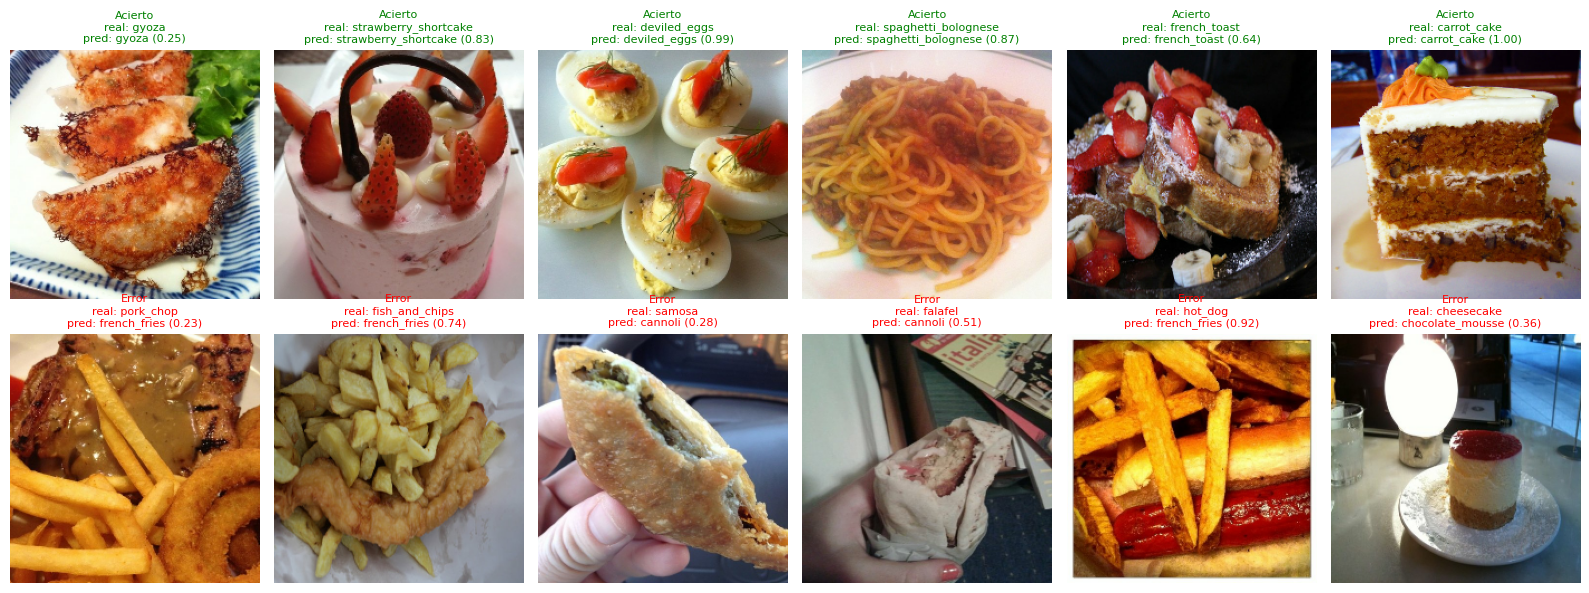

0.79588246 0.45277408


In [27]:
rng = np.random.default_rng(0)
ok = rng.choice(np.where(y_true == y_pred)[0], 6, replace=False)
mal = rng.choice(np.where(y_true != y_pred)[0], 6, replace=False)
elegidos = set(ok) | set(mal)

imgs = {}
i = 0
for x, y in test_ds:
    for k in range(len(y)):
        if i in elegidos:
            imgs[i] = x[k].numpy().astype("uint8")
        i += 1

fig, ejes = plt.subplots(2, 6, figsize=(16, 6))
for fila, (grupo, titulo) in enumerate([(ok, "Acierto"), (mal, "Error")]):
    for col, i in enumerate(grupo):
        ejes[fila, col].imshow(imgs[i])
        ejes[fila, col].set_title(
            f"{titulo}\nreal: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({y_conf[i]:.2f})",
            fontsize=8, color="green" if fila == 0 else "red")
        ejes[fila, col].axis("off")
plt.tight_layout()
plt.show()

print(y_conf[y_true == y_pred].mean(), y_conf[y_true != y_pred].mean())

### Resultado: ejemplos de aciertos y errores

Los aciertos mostrados tienen en su mayoría confianza alta (por ejemplo deviled_eggs con 0,99 y carrot_cake con 1,00). Hay una excepción: gyoza se clasifica bien con solo 0,25 de confianza, es decir, el modelo acierta pero con poca seguridad.

Sobre todo el conjunto de prueba, la confianza promedio es 0,80 en los aciertos y 0,45 en los errores. El modelo tiende a dudar más cuando se equivoca, por lo que la confianza sirve como señal para decidir cuándo mostrar al usuario varias opciones. No es una señal perfecta: hay errores con confianza alta, como hot_dog predicho como french_fries (0,92) y fish_and_chips predicho como french_fries (0,74).

Varios de los errores mostrados ocurren en fotos donde aparece más de un alimento. En pork_chop, fish_and_chips y hot_dog, las papas fritas ocupan buena parte de la imagen y el modelo predice french_fries, que visualmente está presente en la foto. El modelo asigna una sola clase por imagen, mientras que estas fotos contienen más de un alimento. Esto se relaciona con la limitación de un alimento por foto. Los otros errores (samosa y falafel predichos como cannoli, cheesecake como chocolate_mousse) corresponden a alimentos de forma o color parecidos.

Los ejemplos son una muestra aleatoria de 6 aciertos y 6 errores, así que ilustran los casos pero no los cuantifican.

## 5. Inferencia

La inferencia es usar el modelo ya entrenado con una foto nueva, que no pertenece a Food-101. La función predecir_foto carga la imagen, la redimensiona a 224x224 (el tamaño que espera el modelo), obtiene las 101 probabilidades y devuelve las 3 clases con mayor probabilidad (Top-3), cada una con su confianza. Para ordenar las probabilidades se usa argsort, que devuelve las posiciones de menor a mayor probabilidad; se invierte el orden y se toman las 3 primeras.

Se prueba con fotos propias. Una de ellas debería ser un alimento que no esté entre las 101 clases, para ver qué responde el modelo. Como el softmax (la función de salida que convierte los resultados en probabilidades que suman 1) siempre reparte la probabilidad entre las 101 clases, el modelo siempre propone clases del dataset, aunque la imagen sea otra cosa.

Saving helado_1.jpg to helado_1.jpg
Saving pizza_1.jpg to pizza_1.jpg
Saving spaguetti_1.jpg to spaguetti_1.jpg


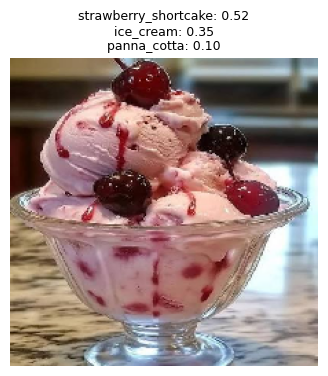

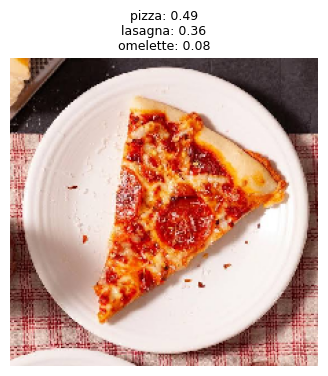

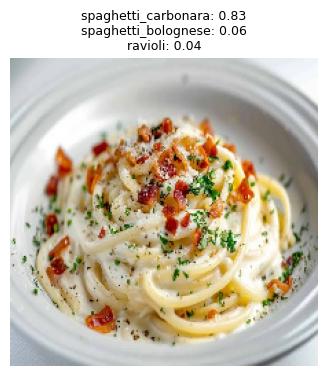

In [28]:
from google.colab import files

def predecir_foto(ruta, k=3):
    img = keras.utils.load_img(ruta, target_size=(224, 224))
    x = keras.utils.img_to_array(img)[np.newaxis]
    p = model(x, training=False).numpy()[0]
    top = p.argsort()[::-1][:k]
    return img, [(class_names[i], float(p[i])) for i in top]

subidas = files.upload()
for ruta in subidas:
    img, top = predecir_foto(ruta)
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title("\n".join(f"{n}: {c:.2f}" for n, c in top), fontsize=9)
    plt.axis("off")
    plt.show()

Fuentes de las imagenes:
*Figura 1.* Pizza de pepperoni [Fotografía]. https://www.tasteofhome.com/recipes/homemade-pizza/

*Figura 2.* Helado cremoso de cereza [Fotografía]. pasteleriadesdecero69. https://www.instagram.com/p/DO4IAsLiPUu/

*Figura 3.* Pizza de pepperoni [Fotografía].  https://pastaslamuneca.com/recetas/pasta-a-la-carbonara/

### Resultado: inferencia con fotos nuevas

Se probó predecir_foto con tres fotos que no pertenecen a Food-101 [ajustar: propias / descargadas de internet / generadas con IA].

- **Pizza:** el Top-1 es pizza (0,49), seguido de lasagna (0,36). Acierta, pero con poca confianza.
- **Spaghetti carbonara:** el Top-1 es spaghetti_carbonara (0,83). Acierta con confianza alta.
- **Helado con cerezas:** el Top-1 es strawberry_shortcake (0,52) y el segundo es ice_cream (0,35). Se equivoca en el Top-1, pero la clase correcta aparece entre las tres propuestas.

En 2 de 3 fotos acierta el Top-1, y en las 3 la clase correcta está en el Top-3. Con tres fotos esto es solo una ilustración del funcionamiento y no una medida de desempeño: la medida es la del conjunto de prueba (Top-1 de 69,7 % y Top-5 de 90,7 %). En las dos fotos con confianza cercana a 0,5 el Top-3 ayuda: ofrecer al usuario las tres opciones permitiría corregir el error del helado con un toque. El umbral de confianza a partir del cual se mostrarían las alternativas no está definido y queda como trabajo futuro.

## 6. Conclusiones

**Resultados.** Un clasificador basado en MobileNetV3 con transfer learning, entrenado 5 épocas con la base congelada, alcanza en el conjunto de prueba de Food-101 una exactitud Top-1 de 69,7 % y Top-5 de 90,7 %. Son resultados preliminares: quedan por debajo del Top-1 de 80 % que mencionaba la retroalimentación como ejemplo, y el Top-5 se acerca al ejemplo de 92 %. En la validación no se observó sobreajuste.

**Dónde acierta y dónde falla.** Los errores más frecuentes ocurren entre clases visualmente parecidas (filet_mignon y steak, ramen y pho, gnocchi y ravioli). La confianza promedio es 0,80 en los aciertos y 0,45 en los errores, por lo que la confianza sirve como señal para ofrecer al usuario varias opciones. En las pruebas con fotos nuevas, la clase correcta apareció en el Top-3 en las tres fotos probadas.

**Limitaciones.**
- Una clase por foto: en imágenes con varios alimentos, el modelo propone uno solo.
- El modelo no puede responder "no lo conozco": el softmax siempre reparte la probabilidad entre las 101 clases, incluso si la imagen no es de comida.
- Food-101 contiene sobre todo platos occidentales y casi no tiene comida colombiana.
- Las métricas se midieron sobre Food-101, no sobre fotos tomadas por usuarios reales.
- Este notebook cubre el reconocimiento del alimento. La conversión a calorías y macronutrientes con una tabla nutricional por porción estándar no se implementó en este hito.

**Trabajo futuro.**
- Afinar el modelo descongelando capas de la base y comparar con los resultados actuales. Podría mejorar la exactitud, pero no está probado.
- Reconocer varios alimentos en una misma foto (multietiqueta o segmentación).
- Ampliar el conjunto con platos locales.
- Definir un umbral de confianza para decidir cuándo mostrar alternativas y cuándo rechazar una imagen.
- Integrar la tabla nutricional y el ajuste de porción.